<a href="https://colab.research.google.com/github/shubhamjadoun5-source/basic_project/blob/main/project2unlox.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Complete and Structured Airbnb Price Prediction Pipeline**

1. **Setup & Data Loading**
2. **Missing Value Imputation & Feature Engineering**
3. **Outlier Trimming (95th Percentile)**
4. **Categorical Encoding (One-Hot Encoding)**
5. **Train/Test Split & Linear Regression Model Training**
6. **Model Evaluation & Visualization**

In [49]:
# === STEP 1: Setup and Loading the Data ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
df_raw = pd.read_csv('/content/AB_NYC_2019.csv')
print("Initial Dataset Shape:", df_raw.shape)

Initial Dataset Shape: (48895, 16)


In [50]:
# === STEP 2: Missing Value Imputation ===
# Copying raw data to avoid modifying the original source
df_processed = df_raw.copy()

# Fill missing reviews_per_month with 0 (since number_of_reviews is 0)
df_processed['reviews_per_month'] = df_processed['reviews_per_month'].fillna(0)

# Fill missing name and host_name text columns
df_processed['name'] = df_processed['name'].fillna('Unknown')

df_processed['host_name'] = df_processed['host_name'].fillna('Unknown')

# Confirm that no null values remain (except in last_review which we will drop/transform)
print("Null values remaining:")
print(df_processed.isnull().sum())

Null values remaining:
id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64


In [51]:
# === STEP 3: Feature Engineering ===

# 1. Transform 'last_review' date column to days_since_last_review
df_processed['last_review'] = pd.to_datetime(df_processed['last_review'], errors='coerce')
reference_date = df_processed['last_review'].max()
df_processed['days_since_last_review'] = (reference_date - df_processed['last_review']).dt.days

# Fill missing days with a placeholder (9999) for listings with zero reviews
df_processed['days_since_last_review'] = df_processed['days_since_last_review'].fillna(9999)

# 2. Drop high cardinality / unused identifier columns
columns_to_drop = ['id', 'name', 'host_id', 'host_name', 'last_review', 'neighbourhood']
df_processed.drop(columns=columns_to_drop, inplace=True, errors='ignore')

print("Columns after feature engineering and drops:", df_processed.columns.tolist())

Columns after feature engineering and drops: ['neighbourhood_group', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'days_since_last_review']


In [52]:
# === STEP 4: Outlier Trimming (95th Percentile) ===
percentile_95 = df_processed['price'].quantile(0.95)

# Trim prices above the 95th percentile and ignore any free listings (price == 0)
initial_count = len(df_processed)
df_final = df_processed[(df_processed['price'] <= percentile_95) & (df_processed['price'] > 0)]
final_count = len(df_final)

print(f"Trimming threshold: ${percentile_95:.2f}")
print(f"Rows before: {initial_count} | Rows after: {final_count}")
print(f"Removed rows: {initial_count - final_count} ({((initial_count - final_count)/initial_count)*100:.2f}%) of data")

Trimming threshold: $355.00
Rows before: 48895 | Rows after: 46443
Removed rows: 2452 (5.01%) of data


In [53]:
# === STEP 5: Categorical Encoding (One-Hot Encoding) ===
categorical_cols = ['neighbourhood_group', 'room_type']
df_final_encoded = pd.get_dummies(df_final, columns=categorical_cols, drop_first=True)

# Verify that all columns in the dataset are numeric
print("Final Columns Info:")
df_final_encoded.info()
display(df_final_encoded.head())

Final Columns Info:
<class 'pandas.core.frame.DataFrame'>
Index: 46443 entries, 0 to 48894
Data columns (total 15 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           46443 non-null  float64
 1   longitude                          46443 non-null  float64
 2   price                              46443 non-null  int64  
 3   minimum_nights                     46443 non-null  int64  
 4   number_of_reviews                  46443 non-null  int64  
 5   reviews_per_month                  46443 non-null  float64
 6   calculated_host_listings_count     46443 non-null  int64  
 7   availability_365                   46443 non-null  int64  
 8   days_since_last_review             46443 non-null  float64
 9   neighbourhood_group_Brooklyn       46443 non-null  bool   
 10  neighbourhood_group_Manhattan      46443 non-null  bool   
 11  neighbourhood_group_Queens         4644

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,days_since_last_review,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,262.0,True,False,False,False,True,False
1,40.75362,-73.98377,225,1,45,0.38,2,355,48.0,False,True,False,False,False,False
2,40.80902,-73.94190,150,3,0,0.00,1,365,9999.0,False,True,False,False,True,False
3,40.68514,-73.95976,89,1,270,4.64,1,194,3.0,True,False,False,False,False,False
4,40.79851,-73.94399,80,10,9,0.10,1,0,231.0,False,True,False,False,False,False


In [54]:
# === STEP 6: Train/Test Split & Model Training ===
X_final = df_final_encoded.drop('price', axis=1)
y_final = df_final_encoded['price']

X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final, y_final, test_size=0.2, random_state=42
)

# Initialize and train Linear Regression
final_model = LinearRegression()
final_model.fit(X_train_final, y_train_final)

# Make predictions
final_predictions = final_model.predict(X_test_final)

# Evaluate performance metrics
final_mse = mean_squared_error(y_test_final, final_predictions)
final_r2 = r2_score(y_test_final, final_predictions)

print("\n--- Final Model Evaluation Results ---")
print(f"Mean Squared Error (MSE): {final_mse:.2f}")
print(f"R-squared (R2) Score: {final_r2:.4f}")


--- Final Model Evaluation Results ---
Mean Squared Error (MSE): 2803.28
R-squared (R2) Score: 0.4618


In [ ]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# 2. Load the Dataset
df = pd.read_csv('/content/AB_NYC_2019.csv')
print("Dataset Dimensions:", df.shape)

In [ ]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [38]:
# Task 1.3: Calculate the percentage of missing values for each column
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_info_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Percentage (%)': np.round(missing_percentage, 2)
})

print("--- Missing Values Percentage (Task 1.3) ---")
display(missing_info_df[missing_info_df['Missing Count'] > 0].sort_values(by='Percentage (%)', ascending=False))

--- Missing Values Percentage (Task 1.3) ---


,Missing Count,Percentage (%)
last_review,10052,20.56


In [ ]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [32]:
# Quick Check: Verified current shape of the dataset
df.shape

(48895, 16)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


Text(0.5, 0, 'Price ($)')

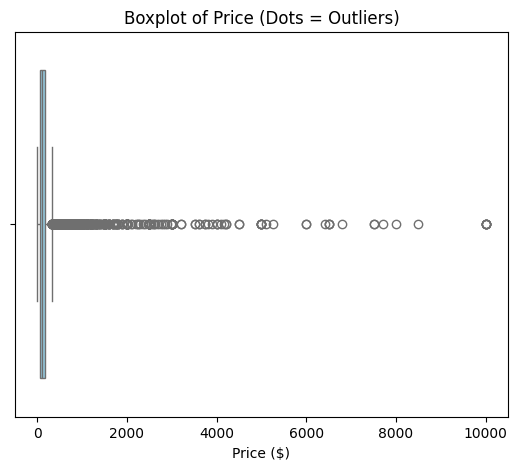

In [26]:
# 5. Outlier Visualization for Price
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['price'], color='skyblue')
plt.title('Boxplot of Price (Dots = Outliers)')
plt.xlabel('Price ($)')

plt.subplot(1, 2, 2)
sns.histplot(df['price'], bins=50, color='salmon', log_scale=(False, True))
plt.title('Histogram of Price (Right side ke bars = Outliers)')
plt.xlabel('Price ($)')
plt.ylabel('Count (Log Scale)')

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Count (Log Scale)')

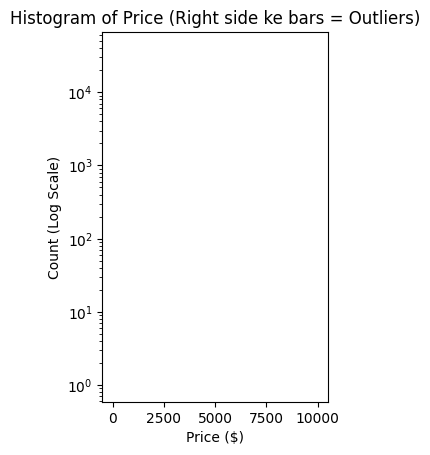

In [27]:
# Histogram
plt.subplot(1, 2, 2)
sns.histplot(df['price'], bins=50, color='salmon', log_scale=(False, True))
plt.title('Histogram of Price (Right side ke bars = Outliers)')
plt.xlabel('Price ($)')
plt.ylabel('Count (Log Scale)')

In [ ]:
from sklearn.model_selection import train_test_split

In [33]:
# 6. Split Data into Train and Test Sets (using the Cleaned DataFrame)
from sklearn.model_selection import train_test_split

X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Total data rows:", len(df))
print("Training data (X_train) rows:", len(X_train))
print("Testing data (X_test) rows:", len(X_test))

Total data rows: 48895
Training data (X_train) rows: 39116
Testing data (X_test) rows: 9779


In [34]:
# 7. Train the Model with cleaned numerical features (including 'reviews_per_month')
from sklearn.linear_model import LinearRegression

# Now we can safely include 'reviews_per_month' because it is fully imputed!
numeric_cols = ['minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'latitude', 'longitude']

model = LinearRegression()
model.fit(X_train[numeric_cols], y_train)

predictions = model.predict(X_test[numeric_cols])
print("Predictions snippet:", predictions[:5])

Predictions snippet: [161.78328671 114.77902676 173.00034164 249.26453762 134.44550032]


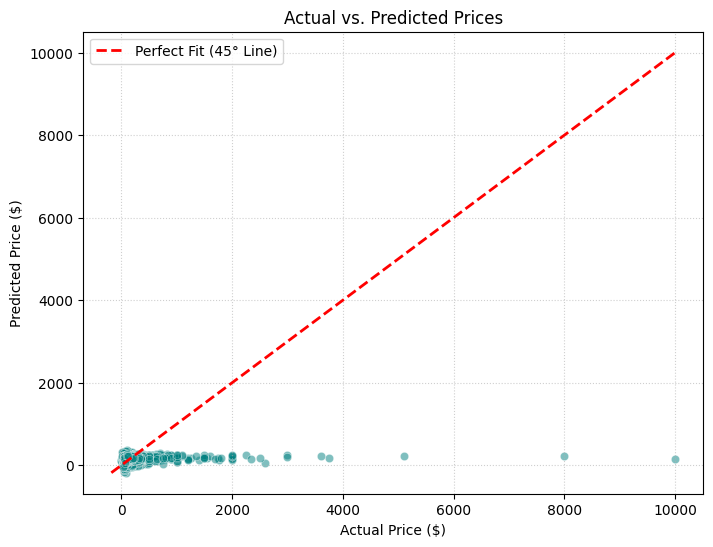

,Actual Price,Predicted Price,Difference (Error)
0,89,161.78,-72.78
1,30,114.78,-84.78
2,120,173.00,-53.00
3,470,249.26,220.74
4,199,134.45,64.55
5,170,98.28,71.72
6,90,144.14,-54.14
7,60,86.41,-26.41
8,150,159.28,-9.28
9,74,51.59,22.41


In [35]:
# 9. Plot Actual vs Predicted prices with a 45-degree line
results_df = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': np.round(predictions, 2),
    'Difference (Error)': np.round(y_test.values - predictions, 2)
})

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test.values, y=predictions, alpha=0.5, color='teal')

max_val = max(max(y_test.values), max(predictions))
min_val = min(min(y_test.values), min(predictions))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Fit (45° Line)')

plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.title('Actual vs. Predicted Prices')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

display(results_df.head(10))

In [36]:
# 8. Evaluate Model Metrics
from sklearn.metrics import r2_score, mean_squared_error

mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Mean Squared Error (MSE): 42550.10
R-squared (R2) Score: 0.0382


In [39]:
# Task 2.2: Handle Missing Values in reviews_per_month
# 1. Show 'number_of_reviews' for rows where 'reviews_per_month' is NaN
print("--- Investigation: number_of_reviews for NaN reviews_per_month ---")
nan_mask = df['reviews_per_month'].isnull()
display(df[nan_mask]['number_of_reviews'].value_counts(dropna=False))

# 2. Fill missing reviews_per_month values with 0 (No mean imputation used)
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# 3. Fill missing text columns
df['name'] = df['name'].fillna('Unknown')
df['host_name'] = df['host_name'].fillna('Unknown')

# Confirm that missing values are resolved
print("\n--- Missing Values Status After Task 2.2 ---")
display(df.isnull().sum())

--- Investigation: number_of_reviews for NaN reviews_per_month ---


,count
number_of_reviews,



--- Missing Values Status After Task 2.2 ---


,0
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [40]:
# Feature Engineering: Convert last_review to days_since_last_review

# 1. Convert to datetime
df['last_review'] = pd.to_datetime(df['last_review'], errors='coerce')

# 2. Define the reference date (latest review date in dataset)
reference_date = df['last_review'].max()
print(f"Reference Date (Latest Review in Dataset): {reference_date}")

# 3. Calculate difference in days
df['days_since_last_review'] = (reference_date - df['last_review']).dt.days

# 4. Fill missing values (for listings with 0 reviews) with a placeholder (e.g., 9999)
df['days_since_last_review'] = df['days_since_last_review'].fillna(9999)

# 5. Drop the original date column
df.drop(columns=['last_review'], inplace=True, errors='ignore')

# Verify the new feature
print("\n--- Feature Engineering Complete ---")
display(df[['number_of_reviews', 'days_since_last_review']].head(10))

Reference Date (Latest Review in Dataset): 2019-07-08 00:00:00

--- Feature Engineering Complete ---


,number_of_reviews,days_since_last_review
0,9,262.0
1,45,48.0
2,0,9999.0
3,270,3.0
4,9,231.0
5,74,16.0
6,49,641.0
7,430,14.0
8,118,717.0
9,160,29.0


In [41]:
# Drop specified identifier and text columns
columns_to_drop = ['id', 'name', 'host_id', 'host_name']
df.drop(columns=columns_to_drop, inplace=True, errors='ignore')

# Verify updated columns and shape
print("Columns dropped successfully!")
print("Remaining Columns:", df.columns.tolist())
print("New Shape:", df.shape)
display(df.head(5))

Columns dropped successfully!
Remaining Columns: ['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'days_since_last_review']
New Shape: (48895, 12)


,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,days_since_last_review
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365,262.0
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355,48.0
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365,9999.0
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194,3.0
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0,231.0


In [42]:
# Check for rows where price is equal to 0
zero_price_df = df[df['price'] == 0]

print(f"Number of rows with price == 0: {len(zero_price_df)}")
if len(zero_price_df) > 0:
    print("\nSample of rows with price == 0:")
    display(zero_price_df.head(10))

    print("\nDistribution of room types for 0 price listings:")
    display(zero_price_df['room_type'].value_counts())
else:
    print("No rows found with price == 0.")

Number of rows with price == 0: 11

Sample of rows with price == 0:


,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,days_since_last_review
23161,Brooklyn,Bedford-Stuyvesant,40.69023,-73.95428,Private room,0,4,1,0.05,4,28,548.0
25433,Bronx,East Morrisania,40.83296,-73.88668,Private room,0,2,55,2.56,4,127,14.0
25634,Brooklyn,Bushwick,40.69467,-73.92433,Private room,0,2,16,0.71,5,0,51.0
25753,Brooklyn,Greenpoint,40.72462,-73.94072,Private room,0,2,12,0.53,2,0,619.0
25778,Brooklyn,Williamsburg,40.70838,-73.94645,Entire home/apt,0,5,3,0.15,1,73,552.0
25794,Brooklyn,Bedford-Stuyvesant,40.68173,-73.91342,Private room,0,1,93,4.28,6,176,23.0
25795,Brooklyn,Bedford-Stuyvesant,40.68279,-73.91170,Private room,0,1,95,4.37,6,232,17.0
25796,Brooklyn,Bedford-Stuyvesant,40.68258,-73.91284,Private room,0,1,95,4.35,6,222,15.0
26259,Manhattan,Murray Hill,40.75091,-73.97597,Entire home/apt,0,3,0,0.00,1,0,9999.0
26841,Brooklyn,Bushwick,40.69211,-73.90670,Shared room,0,30,2,0.11,6,333,16.0



Distribution of room types for 0 price listings:


,count
room_type,
Private room,7
Entire home/apt,2
Shared room,2


In [43]:
# Reverting: Reload original 'price' column from the source dataset
original_data = pd.read_csv('/content/AB_NYC_2019.csv')
df['price'] = original_data['price']

# Verify restoration
print("Price column successfully restored to original values!")
print(df['price'].describe())

Price column successfully restored to original values!
count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64


95th Percentile threshold for Price: $355.00

Initial rows: 48895
Remaining rows after trimming: 46454
Removed rows: 2441 (4.99% of data)

--- Price Stats After Trimming ---
count    46454.000000
mean       122.583760
std         71.987526
min          0.000000
25%         65.000000
50%        100.000000
75%        160.000000
max        355.000000
Name: price, dtype: float64


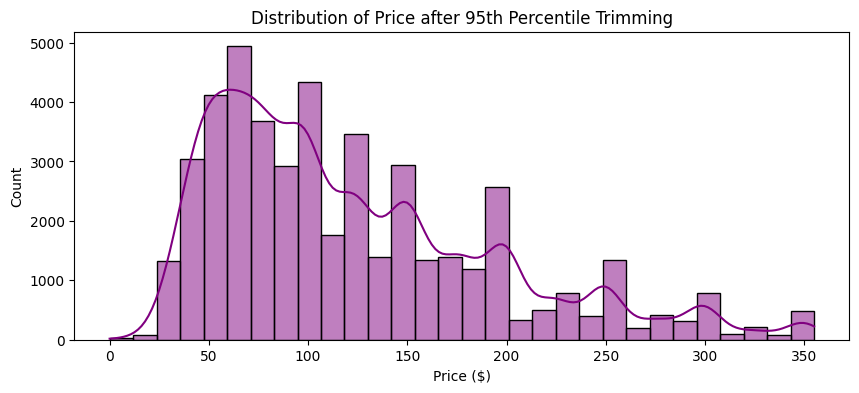

In [44]:
# Calculate 95th percentile of price
percentile_95 = df['price'].quantile(0.95)
print(f"95th Percentile threshold for Price: ${percentile_95:.2f}")

# Trim (Remove) rows above the 95th percentile
initial_rows = len(df)
df = df[df['price'] <= percentile_95]
final_rows = len(df)

print(f"\nInitial rows: {initial_rows}")
print(f"Remaining rows after trimming: {final_rows}")
print(f"Removed rows: {initial_rows - final_rows} ({((initial_rows - final_rows)/initial_rows)*100:.2f}% of data)")

# Verify updated stats
print("\n--- Price Stats After Trimming ---")
print(df['price'].describe())

# Visualize the distribution after trimming
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 4))
sns.histplot(df['price'], bins=30, kde=True, color='purple')
plt.title('Distribution of Price after 95th Percentile Trimming')
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.show()

In [45]:
# Drop the 'neighbourhood' column due to high cardinality
if 'neighbourhood' in df.columns:
    df.drop(columns=['neighbourhood'], inplace=True)
    print("'neighbourhood' column successfully dropped!")
else:
    print("'neighbourhood' column already dropped or does not exist.")

# Display updated shape and columns
print("Updated Shape:", df.shape)
print("Remaining Columns:", df.columns.tolist())


'neighbourhood' column successfully dropped!
Updated Shape: (46454, 11)
Remaining Columns: ['neighbourhood_group', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'days_since_last_review']


In [46]:
# 1. Apply One-Hot Encoding to categorical columns
categorical_cols = ['neighbourhood_group', 'room_type']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

print("Encoded Dataset Dimensions:", df_encoded.shape)
print("Columns after encoding:")
print(df_encoded.columns.tolist())

# 2. Split data into Features (X) and Target (y)
X_clean = df_encoded.drop('price', axis=1)
y_clean = df_encoded['price']

# 3. Perform Train-Test Split (80% Train, 20% Test)
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42
)

print(f"\nTraining rows: {X_train_clean.shape[0]}")
print(f"Testing rows: {X_test_clean.shape[0]}")

Encoded Dataset Dimensions: (46454, 15)
Columns after encoding:
['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'days_since_last_review', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room']

Training rows: 37163
Testing rows: 9291


In [47]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# 1. Initialize the new Linear Regression model
clean_model = LinearRegression()

# 2. Train the model using the fully processed training dataset
clean_model.fit(X_train_clean, y_train_clean)

# 3. Predict on the clean testing dataset
clean_predictions = clean_model.predict(X_test_clean)

# 4. Calculate performance metrics
clean_mse = mean_squared_error(y_test_clean, clean_predictions)
clean_r2 = r2_score(y_test_clean, clean_predictions)

print("--- Cleaned & Processed Model Evaluation ---")
print(f"Mean Squared Error (MSE): {clean_mse:.2f}")
print(f"R-squared (R2) Score: {clean_r2:.4f}")

# 5. Contrast against our first uncleaned baseline model
print("\n--- Comparison with Baseline Model ---")
print(f"Baseline MSE: 42550.10  -> New MSE: {clean_mse:.2f}")
print(f"Baseline R2 Score: 0.0382 -> New R2 Score: {clean_r2:.4f}")

--- Cleaned & Processed Model Evaluation ---
Mean Squared Error (MSE): 2789.67
R-squared (R2) Score: 0.4674

--- Comparison with Baseline Model ---
Baseline MSE: 42550.10  -> New MSE: 2789.67
Baseline R2 Score: 0.0382 -> New R2 Score: 0.4674


In [48]:
# Display the first few rows of the encoded dataset
display(df_encoded.head())

# Check the data types of all remaining columns
df_encoded.info()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,days_since_last_review,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,262.0,True,False,False,False,True,False
1,40.75362,-73.98377,225,1,45,0.38,2,355,48.0,False,True,False,False,False,False
2,40.80902,-73.94190,150,3,0,0.00,1,365,9999.0,False,True,False,False,True,False
3,40.68514,-73.95976,89,1,270,4.64,1,194,3.0,True,False,False,False,False,False
4,40.79851,-73.94399,80,10,9,0.10,1,0,231.0,False,True,False,False,False,False


<class 'pandas.core.frame.DataFrame'>
Index: 46454 entries, 0 to 48894
Data columns (total 15 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           46454 non-null  float64
 1   longitude                          46454 non-null  float64
 2   price                              46454 non-null  int64  
 3   minimum_nights                     46454 non-null  int64  
 4   number_of_reviews                  46454 non-null  int64  
 5   reviews_per_month                  46454 non-null  float64
 6   calculated_host_listings_count     46454 non-null  int64  
 7   availability_365                   46454 non-null  int64  
 8   days_since_last_review             46454 non-null  float64
 9   neighbourhood_group_Brooklyn       46454 non-null  bool   
 10  neighbourhood_group_Manhattan      46454 non-null  bool   
 11  neighbourhood_group_Queens         46454 non-null  bool   
